# Guide Enumeration Doesn't work like I think it does

In [1]:
import pyro
import pyro.distributions as dist
import pyro.distributions.constraints as constraints
import pyro.infer as infer
import pyro.optim as optim
import torch

import matplotlib.pyplot as plt

import logging

logging.basicConfig(format='%(message)s', level=logging.INFO)

param_store = pyro.get_param_store()

In [2]:
def model(*args, **kwargs):
    y = pyro.sample("y", dist.Normal(-2, 5))
    return {"y":y}

def simple_guide(*args, **kwargs):
    y_loc = pyro.param("y_loc", torch.tensor(0.0))
    y_scale = pyro.param("y_scale", torch.tensor(1.0), constraints.positive)
    y = pyro.sample("y", dist.Normal(y_loc, y_scale))
    return {"y":y}

def enum_guide(*args, num_samples = 1, expand = True, enumerate = "parallel", **kwargs):
    x_loc = pyro.param("x_loc", torch.tensor(0.0))
    x_scale = pyro.param("x_scale", torch.tensor(1.0), constraints.positive)
    x = pyro.sample("x", dist.Normal(x_loc, x_scale), 
                    infer = {"is_auxiliary":True, "expand": expand, "enumerate": enumerate, "num_samples": num_samples})
    y = pyro.sample("y", dist.Normal(x, 4))
    return {"y":y}


In [3]:
def do_svi(svi, *args, num_steps = 10000, **kwargs):
    losses = []
    for _ in range(num_steps):
        loss = svi.step(*args, **kwargs)
        losses.append(loss)
    return losses

def print_params():
    for name,val in pyro.get_param_store().items():
        print(f"{name}: {val}")

y_loc: -1.943419337272644
y_scale: 5.041705131530762
y mean = -1.968575358390808, std = 5.056609153747559, shape = torch.Size([10000])


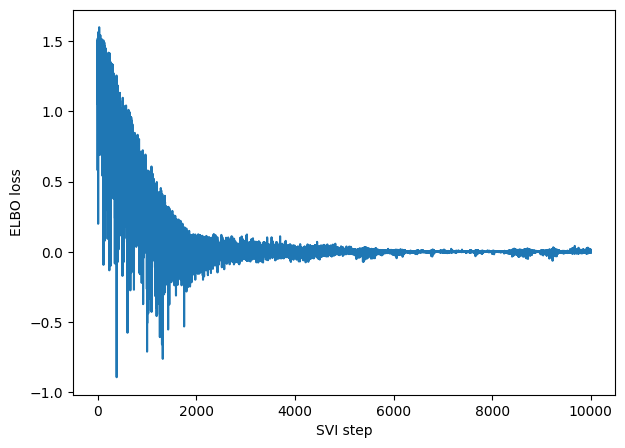

In [4]:
# Test simple guide (guide that doesn't use a latent x at all)
# Expect y_loc = -2, y_scale = 5

svi = infer.SVI(model, simple_guide, optim.Adam({"lr": 0.001}), infer.Trace_ELBO(num_particles=5))

with param_store.scope() as simple_scope:
    losses = do_svi(svi)
    print_params()
    pred = infer.Predictive(model, guide=simple_guide, num_samples = 10000, return_sites = ["y"])
    samples = pred.get_samples()['y']
    print(f"y mean = {samples.mean()}, std = {samples.std()}, shape = {samples.shape}")
    

plt.figure(figsize=(7,5))
plt.plot(losses)
plt.xlabel("SVI step")
plt.ylabel("ELBO loss");

Guessed max_plate_nesting = 0


x_loc: -1.9988359212875366
x_scale: 4.974017143249512
y mean = -2.0721969604492188, std = 6.346295356750488, shape = torch.Size([10000])


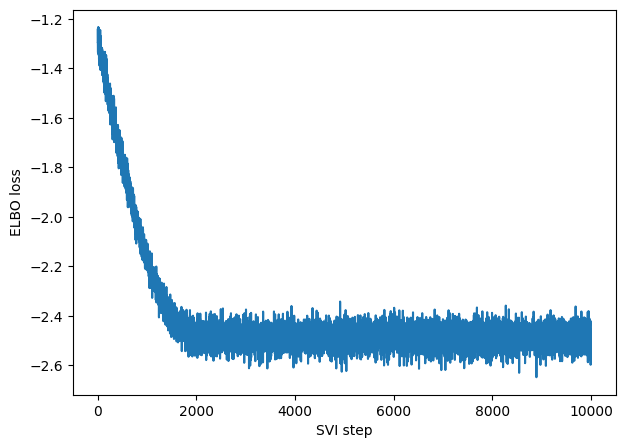

In [5]:
# Test enum guide (guide that enumerates over samples of x)
# Expect x_loc = -2, x_scale = 3

enum_svi = infer.SVI(model, enum_guide, optim.Adam({"lr": 0.001}), infer.TraceEnum_ELBO(num_particles=5))

with param_store.scope() as enum_scope:
    losses = do_svi(enum_svi, num_samples = 100, expand=True, enumerate="parallel")
    print_params()
    pred = infer.Predictive(model, guide=enum_guide, num_samples = 10000, return_sites = ["y"])
    samples = pred.get_samples()['y']
    print(f"y mean = {samples.mean()}, std = {samples.std()}, shape = {samples.shape}")

plt.figure(figsize=(7, 5))
plt.plot(losses)
plt.xlabel("SVI step")
plt.ylabel("ELBO loss");